In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [51]:
normal_data = {
"CPU(%)" :  [38,42,45,48,50,53,55,58,46,51],
"Memory(%)" : [42,45,47,49,52,50,56,54,44,48]
}
df_train = pd.DataFrame(normal_data)

In [52]:
print(df_train)

   CPU(%)  Memory(%)
0      38         42
1      42         45
2      45         47
3      48         49
4      50         52
5      53         50
6      55         56
7      58         54
8      46         44
9      51         48


In [53]:
print(df_train.head())

   CPU(%)  Memory(%)
0      38         42
1      42         45
2      45         47
3      48         49
4      50         52


In [54]:
new_data = {
"CPU(%)" : [92,10],
"Memory(%)" : [91,88]
}
df_test=pd.DataFrame(new_data)

In [55]:
print(df_test)

   CPU(%)  Memory(%)
0      92         91
1      10         88


In [56]:
X_train = df_train.to_numpy()
X_train

array([[38, 42],
       [42, 45],
       [45, 47],
       [48, 49],
       [50, 52],
       [53, 50],
       [55, 56],
       [58, 54],
       [46, 44],
       [51, 48]])

In [57]:
mu = np.mean(X_train, axis=0) # Öğrenme aşaması
variance = np.var(X_train, axis=0)

print("Mean:", mu)
print("Variance:", variance)

Mean: [48.6 48.7]
Variance: [33.24 17.81]


In [58]:
def gaussian(x, mu, variance):
    return (1 / np.sqrt(2 * np.pi * variance)) * \
           np.exp(-((x - mu) ** 2) / (2 * variance))

In [59]:
X_test = df_test.to_numpy()
print(X_test)

densities = gaussian(X_test, mu, variance)

print(densities)

[[92 91]
 [10 88]]
[[3.43028770e-14 1.44470354e-23]
 [1.27821743e-11 1.39471818e-20]]


In [60]:
p = np.prod(densities, axis=1) # p(x) = p(Cpu) * p(Memory)

print("Anomaly scores:", p)

Anomaly scores: [4.95574878e-37 1.78275309e-31]


In [61]:
epsilon = 0.00001

In [62]:
predictions = p < epsilon
print("Anomaly predictions:", predictions)
# True -> Anomali
# False -> Normal


Anomaly predictions: [ True  True]


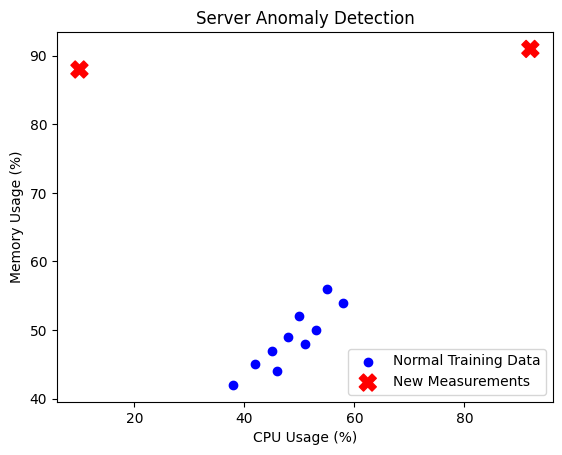

In [63]:
plt.scatter(
    df_train["CPU(%)"],
    df_train["Memory(%)"],
    color="blue",
    label="Normal Training Data"
)

plt.scatter(
    df_test["CPU(%)"],
    df_test["Memory(%)"],
    c=np.where(predictions, "red", "green"),
    marker="X",
    s=150,
    label="New Measurements"
)

plt.xlabel("CPU Usage (%)")
plt.ylabel("Memory Usage (%)")
plt.title("Server Anomaly Detection")
plt.legend()
plt.show()

In [67]:
new_measurement = np.array([[49, 50]])

new_density = gaussian(
    new_measurement,
    mu,
    variance
)

print(new_density)

new_p = np.prod(new_density, axis=1)

print("Density:", new_p)
print("Is anomaly?", new_p < epsilon)

[[0.06902944 0.09015149]]
Density: [0.00622311]
Is anomaly? [False]
